In [1]:
# import numpy as np
import pandas as pd
import matplotlib.gridspec as gridspec

import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvas
from scipy.spatial import distance
import random as rand
import pickle
from scipy import stats
import time


# allow us to re-use the framework from the src directory
import sys, os
sys.path.append(os.path.abspath(os.path.join('../')))

import max_ent.examples.grid_9_by_9 as G
from max_ent.utility.support import *
from max_ent.gridworld import Directions


rand.seed(123)
np.random.seed(123)

In [2]:

'''label='length'
list_df = [df3[label],df4[label]]
list_mean=[(np.mean(x)+np.std(x))*1.1 for x in list_df]

print(np.max(list_mean))
'''
'''def min_max(label, df, df2, df3, df4, df7):
    list_df = [df[label],df2[label],df3[label],df4[label],df7[label]]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label'''

def min_max(label, df):
    list_df = df[label]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    #print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label

In [3]:
def plot_subtype(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna = False):
    
    print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(60, 15))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) & ((df['type']=='SOFAI w/ S1 ra=0.0') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.25') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')
        
        # real subplot #2
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.5') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.75') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], ci=None, hue=hue,markers=True, dashes=False)
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=1.0') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue,markers=True, dashes=False)
        if max_label: g.set_ylim([min_label, max_label])

    plt.savefig(filename+'.pdf')
    plt.show()

def plot_type(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna=False):
         
    ci=None
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(60, 30))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)
    #print(df['type'])

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.0'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.25')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.25'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.5')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.5'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.75')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.75'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=1.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=1.0'], hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')

    plt.savefig(filename+'.pdf')
    plt.show()



In [4]:
def f(count_stat):
    Z = []

    for x in range(9):
        temp_grid = []
        for y in range(9):
            #print(f"({x},{y})")
            temp_grid.append(np.sum(count_stat[0][y][8-x]))
            
        #print(temp_grid)
        Z.append(temp_grid)
    return np.array(Z)

In [5]:
def plot_results(df, x, y, min_label, max_label, bootstrap = 0):
    
    fig=plt.figure(figsize=(12, 7))
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    temp_df = df.loc[(df['type']!="S1 noMyopic")&(df['type']!="const")&(df['type']!="nominal")& (df['type']!="S1 Myopic") & (df['type']!="S2")& (df['traj_n']>=bootstrap)]
    #print("Prima")
    #g=sns.lineplot(x=x, y=y, data=df, hue="type",markers=True, dashes=False)
    g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);
    #print("Dopo")
    #g.set_xticklabels([f"({(i)/10:0.1f}, {1 - (i)/10:0.1f})" for i in range(11)])
    
    constrained_line = np.mean(df.loc[(df['type']=="const")][y])
    nominal_line = np.mean(df.loc[(df['type']=="nominal")][y])
    #print(f"constrained_line: {constrained_line} {y}")
    #print(f"nominal_line: {nominal_line} {y}")
    #s1_line = np.mean(df.loc[(df['type']=="s1")& (df['traj_n']>=bootstrap)][y])
    s2_line = np.mean(df.loc[(df['type']=="S2")& (df['traj_n']>=0)][y])
    #mixed_line = np.median(temp_df.loc[(temp_df['type']=="mixed")& (temp_df['traj_n']>=bootstrap)][y])
    #s1nb_line_noMyopic = np.mean(df.loc[(df['type']=="S1 noMyopic")& (df['traj_n']>=0)][y])
    #s1nb_line_Myopic = np.mean(df.loc[(df['type']=="S1 Myopic")& (df['traj_n']>=0)][y])
    
    #print(f"s2: {s2_line} s1:{s1nb_line}")
    
    g.axhline(constrained_line, color='r', linestyle='--', label="RL Constrained")
    g.axhline(nominal_line, color='b', linestyle='--', label="RL Nominal")
    #g.axhline(s1_line, color='b', linestyle='--', label="S1")
    #g.axhline(mixed_line, color='g', linestyle='--', label="Mixed")
    #g.axhline(s1nb_line_noMyopic, color='b', linestyle='-.', label="S1 no Myopic")
    #g.axhline(s1nb_line_Myopic, color='black', linestyle='-.', label="S1 Myopic")
    g.axhline(s2_line, color='g', linestyle='-.', label="S2")
    #g.set_ylim([min_label, max_label])

    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    #plt.title(label=y+" varying "+x)
    
    '''h, l = g.get_legend_handles_labels()
    labels=["S1", "S2","SOFAI 10","SOFAI 01","SOFAI 02"]
    g.legend(h, labels)'''
    plt.legend()
    plt.grid(alpha=0.3)
    #g.set_xticks(range(11)) # <--- set the ticks first

    #plt.xlabel("W(Nominal, Constraints)")
    #plt.ylabel("Avg JS dist")
    plt.show()
    #fig.savefig(os.path.join("./", f"{y}_varying_{x}.png"), bbox_inches = 'tight')
    fig.savefig(os.path.join("./", f"{y}.pdf"), bbox_inches = 'tight')

In [6]:
def runSOFAI(n, c, mca_01_myopic, threshold1, threshold2, threshold3, threshold4, threshold5, ra, n_trajectories, trial, mca_s2, title, constraints, n_grid=None):
    s1_ra0 = System1Solver(myopic=False, ra=ra)
    if mca_01_myopic is None: 
        mca_01_myopic = MCA(n=n, c=c, s1=s1_ra0, s2=mca_s2.s2, demo=None, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5=1)
    else:
        mca_01_myopic.setGrid(grid=n, constraints=c)  
        
    demo_mca_01_myopic = mca_01_myopic.generate_trajectories(n_trajectories, discard_not_feasable=False)
    #temp_matrix_mca_01_myopic = count_states(demo_mca_01_myopic.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
    temp_dict=build_dict(type_mca=title, agent=mca_01_myopic, t3= threshold3, demo = demo_mca_01_myopic, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
    #f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
    #df = pd.concat([df, temp_dict])

    temp_jsdiv = {}
    temp_jsdiv['t3'] = threshold3
    temp_jsdiv['t4'] = threshold4
    temp_jsdiv['jsdiv'] = js_divergence((mca_s2.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_s2.modelSelf.ntra_per_transition + 1E-10), (mca_01_myopic.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_01_myopic.modelSelf.ntra_per_transition + 1E-10))
    temp_jsdiv['type'] = title
    temp_jsdiv = pd.DataFrame(data=temp_jsdiv, index=[0])
    
    return mca_01_myopic, temp_dict, temp_jsdiv, demo_mca_01_myopic

In [7]:
n_grids = 10

n_trials = 500 #

n_trajectories = 1
goal = 40

bootstrap = 0
n_constraints = 27
n_actions = 4

threshold1 = 0 # 
threshold2 = 0.95 #0.95 # THIS REMOVE SECOND CONDITION
#threshold3 = 0.1
#list_threshold3 = [0.1, 0.3, 0.6, 0.9] # try with 0.9 or 1.0 / myopic and non-myopic S1
list_threshold3 = [1,] # try with 0.9 or 1.0 / myopic and non-myopic S1
threshold4 = 0 # 

p_slip = 0.1

In [8]:

df = pd.DataFrame()
df2 = pd.DataFrame()
df3 = pd.DataFrame()
df4 = pd.DataFrame()
df7 = pd.DataFrame()

In [10]:

time_tot = int(round(time.time() * 1000))

df = pd.DataFrame()
js_div = pd.DataFrame()
mca = []
size = 9

mca_1 = None
mca_2 = None
mca_3 = None
mca_4 = None
mca_5 = None

list_initial_state = [0,1,2,3,4,5,6,7,8,9,18,27,36,45,54,63,72,73,74,75,76,77,78,79,80,17,26,35,44,53,62,71]

for n_grid in range(n_grids):

    resetModelSelf = True
    mca_agents = [None for i in range(20)]

    blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)
    constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}

    

    #list_available = [x for x in range(size ** 2)]
    list_available = np.array(list_initial_state)
    list_available = np.setdiff1d(list_available, blue)
    list_available = np.setdiff1d(list_available, green)
    list_available = np.setdiff1d(list_available, cs)
    list_available = np.setdiff1d(list_available, [goal])

    demo_list =[]
    
    #generate nomminal 
    time_exp = int(round(time.time() * 1000))
    n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 
    temp_matrix = count_states(demo_n.trajectories, n_cfg.mdp, n, constraints)
    '''temp_dict=build_dict(temp_matrix, type_mca='nominal')
    temp_dict['time'] = time_exp / n_trajectories
    df = pd.concat([df, temp_dict])'''

    Z_distr = f(temp_matrix)
    Z_distr = np.array(Z_distr)
    Z_distr = Z_distr + 1E-3
    Z_distr[8-int(start/9)][int(start%9)]=0
    Z_distr[8-int(goal/9)][int(goal%9)] = 0

    #plt.imshow(Z_distr/np.sum(Z_distr), cmap='hot', interpolation='nearest')
    #plt.show()

    #Z_distr/np.sum(Z_distr)
    distr = np.array(Z_distr/np.sum(Z_distr))

    new_distr = []
    for idistr in range(len(distr)):
        new_distr.append(distr[len(distr)-idistr-1])

    new_distr = np.array(new_distr)


    ##cs = np.random.choice(np.arange(0,81), replace=False, p = new_distr.flatten(), size = n_constraints)
    #constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}
    print(f"Start: {start} Goal: {goal} \nConstraints: {constraints}")
    #exit()

    #generate constrained grid
    cc = [1, 2]
    time_exp = int(round(time.time() * 1000))
    c, c_cfg, demo_c, f2 = create_world('Constrained', blue, green, cs, ca, cc, start=start, goal=goal, check=True, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 

    #COMPUTE STATISTICS FOR NOMINAL
    temp_matrix = count_states(demo_n.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='nominal', demo = demo_n, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    #COMPUTE STATISTICS FOR CONSTRAINED
    temp_matrix = count_states(demo_c.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='const', demo = demo_c, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    for trial in range(n_trials):
        #print(f"Iteration {trial}")
        #generate constraints

        #start = np.random.choice(list_available)
        #start = np.random.choice(list_initial_state)
        '''generate = True
        while generate:
            # generate start state from the list of non-constrained states
            start = np.random.choice(list_available)
            start_x = start % size
            start_y = start // size

            goal_x = goal % size
            goal_y = goal // size

            if abs(start_x-goal_x) > 3 or abs(start_y-goal_y) > 3:
                generate = False'''

        '''blue = [21,  9, 59,  1,  0, 20]
        green = [42, 18, 76, 41, 23, 30]
        cs = [63, 74, 13, 39, 48, 38]
        ca = [Directions.DOWN_LEFT, Directions.UP_LEFT]'''
        ##start =7
        ##goal = 65


        if resetModelSelf: 
            mca_s2 = MCA(n=n, c=c, demo=None, threshold5=1, only_s2=True)
        else:
            mca_s2.setGrid(grid=n, constraints=c)

        demo_mca_s2 = mca_s2.generate_trajectories(n_trajectories)
        #temp_matrix_mca_s2 = count_states(demo_mca_s2.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
        temp_dict=build_dict( type_mca='S2', agent=mca_s2 , demo = demo_mca_s2, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
        #f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
        df = pd.concat([df, temp_dict])

        for i_threshold3 in range(len(list_threshold3)):

            print(f"\n ************** Threshold {i_threshold3}: Trial {trial} grid {n_grid} ******************")
            threshold3 = list_threshold3[i_threshold3]

            mca_agents[i_threshold3 * 5 + 0], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 0], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.0', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 1], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 1], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.25', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 2], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 2], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.5', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 3], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 3], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.75', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 4], temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 4], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=1.0', constraints= constraints)
            if i_threshold3 == len(list_threshold3)-1: demo_list = demo_list + demo.trajectories
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            if ((trial+1) %25 ==0): 
                r=mca_agents[i_threshold3 * 5 + 0].reflect(last=25, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 1].reflect(last=25, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 2].reflect(last=25, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 3].reflect(last=25, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 4].reflect(last=25, verbose=False)
                print(f"Temperature: {mca_agents[i_threshold3 * 5 + 4].temperature}")

            resetModelSelf = False

        time_exp = int(round(time.time() * 1000))
        start = np.random.choice(np.setdiff1d(list_initial_state, cs))
        n.start[0] = start
        print(f"start {start}")


'''f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
#f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_Myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_noMyopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
'''
time_tot = int(round(time.time() * 1000)) - time_tot
print(f"Total time: {time_tot}")


[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]
Start: 75 Goal: 40 
Constraints: {'blue': [], 'green': [], 'cs': array([57, 55, 80, 21,  7, 65, 39,  6, 67, 50, 26, 60, 70, 37, 43, 47, 71,
       36,  0, 45, 28, 16, 23, 15, 77, 74,  9]), 'ca': [DOWN, RIGHT, LEFT, UP]}
[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]


/Users/aloreggia/Documents/GitHub/wmca/max_ent/utility/support.py:104: RuntimeWarning: invalid value encountered in long_scalars
  dict_mca['avg_time'] = time_s1 / usage_s1
/Users/aloreggia/Documents/GitHub/wmca/max_ent/utility/support.py:106: RuntimeWarning: invalid value encountered in double_scalars
  dict_mca['avg_reward'] = reward_s1 / usage_s1



 ************** Threshold 0: Trial 0 grid 0 ******************
start 17

 ************** Threshold 0: Trial 1 grid 0 ******************
start 17

 ************** Threshold 0: Trial 2 grid 0 ******************


/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:178: RuntimeWarning: divide by zero encountered in double_scalars
  action_thresholds[1] = expected_avg_reward / current_reward
/Users/aloreggia/Documents/GitHub/wmca/max_ent/utility/support.py:122: RuntimeWarning: invalid value encountered in long_scalars
  dict_mca['avg_time'] = time_s2 / usage_s2
/Users/aloreggia/Documents/GitHub/wmca/max_ent/utility/support.py:124: RuntimeWarning: invalid value encountered in double_scalars
  dict_mca['avg_reward'] = reward_s2 / usage_s2


start 8

 ************** Threshold 0: Trial 3 grid 0 ******************
start 75

 ************** Threshold 0: Trial 4 grid 0 ******************
start 75

 ************** Threshold 0: Trial 5 grid 0 ******************
start 35

 ************** Threshold 0: Trial 6 grid 0 ******************


...

start 0

 ************** Threshold 0: Trial 234 grid 9 ******************
start 74

 ************** Threshold 0: Trial 235 grid 9 ******************
start 17

 ************** Threshold 0: Trial 236 grid 9 ******************
start 76

 ************** Threshold 0: Trial 237 grid 9 ******************
start 27

 ************** Threshold 0: Trial 238 grid 9 ******************
start 0

 ************** Threshold 0: Trial 239 grid 9 ******************
start 27

 ************** Threshold 0: Trial 240 grid 9 ******************
start 1

 ************** Threshold 0: Trial 241 grid 9 ******************
start 27

 ************** Threshold 0: Trial 242 grid 9 ******************
start 36

 ************** Threshold 0: Trial 243 grid 9 ******************
start 77

 ************** Threshold 0: Trial 244 grid 9 ******************
start 77

 ************** Threshold 0: Trial 245 grid 9 ******************
start 63

 ************** Threshold 0: Trial 246 grid 9 ******************
start 62

 ************** Th

start 35

 ************** Threshold 0: Trial 288 grid 9 ******************
start 26

 ************** Threshold 0: Trial 289 grid 9 ******************
start 63

 ************** Threshold 0: Trial 290 grid 9 ******************
start 62

 ************** Threshold 0: Trial 291 grid 9 ******************
start 17

 ************** Threshold 0: Trial 292 grid 9 ******************
start 74

 ************** Threshold 0: Trial 293 grid 9 ******************
start 27

 ************** Threshold 0: Trial 294 grid 9 ******************
start 54

 ************** Threshold 0: Trial 295 grid 9 ******************
start 53

 ************** Threshold 0: Trial 296 grid 9 ******************
start 8

 ************** Threshold 0: Trial 297 grid 9 ******************
start 63

 ************** Threshold 0: Trial 298 grid 9 ******************
start 18

 ************** Threshold 0: Trial 299 grid 9 ******************
(275, 300)
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warnin


 ************** Threshold 0: Trial 350 grid 9 ******************
start 77

 ************** Threshold 0: Trial 351 grid 9 ******************
start 8

 ************** Threshold 0: Trial 352 grid 9 ******************
start 17

 ************** Threshold 0: Trial 353 grid 9 ******************
start 76

 ************** Threshold 0: Trial 354 grid 9 ******************
start 8

 ************** Threshold 0: Trial 355 grid 9 ******************
start 26

 ************** Threshold 0: Trial 356 grid 9 ******************
start 53

 ************** Threshold 0: Trial 357 grid 9 ******************
start 0

 ************** Threshold 0: Trial 358 grid 9 ******************
start 36

 ************** Threshold 0: Trial 359 grid 9 ******************
start 62

 ************** Threshold 0: Trial 360 grid 9 ******************
start 53

 ************** Threshold 0: Trial 361 grid 9 ******************
start 0

 ************** Threshold 0: Trial 362 grid 9 ******************
start 76

 ************** Threshold 0:

Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
improvements [1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1]
(400, 425)
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
improvements [0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0]
(400, 425)
Warning trajectory too long
Warning trajectory too long
improvements [0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0]
(400, 425)
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long


start 74

 ************** Threshold 0: Trial 478 grid 9 ******************
start 7

 ************** Threshold 0: Trial 479 grid 9 ******************
start 18

 ************** Threshold 0: Trial 480 grid 9 ******************
start 63

 ************** Threshold 0: Trial 481 grid 9 ******************
start 54

 ************** Threshold 0: Trial 482 grid 9 ******************
start 17

 ************** Threshold 0: Trial 483 grid 9 ******************
start 78

 ************** Threshold 0: Trial 484 grid 9 ******************
start 7

 ************** Threshold 0: Trial 485 grid 9 ******************
start 77

 ************** Threshold 0: Trial 486 grid 9 ******************
start 36

 ************** Threshold 0: Trial 487 grid 9 ******************
start 35

 ************** Threshold 0: Trial 488 grid 9 ******************
start 9

 ************** Threshold 0: Trial 489 grid 9 ******************
start 36

 ************** Threshold 0: Trial 490 grid 9 ******************
start 9

 ************** Thr

In [ ]:
temp_demo = Demonstration(demo_list, demo.policy)
#df.to_csv("dati_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")
#js_div.to_csv("jsdiv_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")

In [ ]:
G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

In [ ]:
temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==0.9) &  ((df['type']=='SOFAI w/ S1') )  ]

In [ ]:
#plt.plot(temp_df.loc[temp_df['sub_type']=='s1']['usage'])

In [ ]:
#x='traj_n'
#y='perc_usage'

#g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue="sub_type",markers=True, dashes=False)

[0, None]


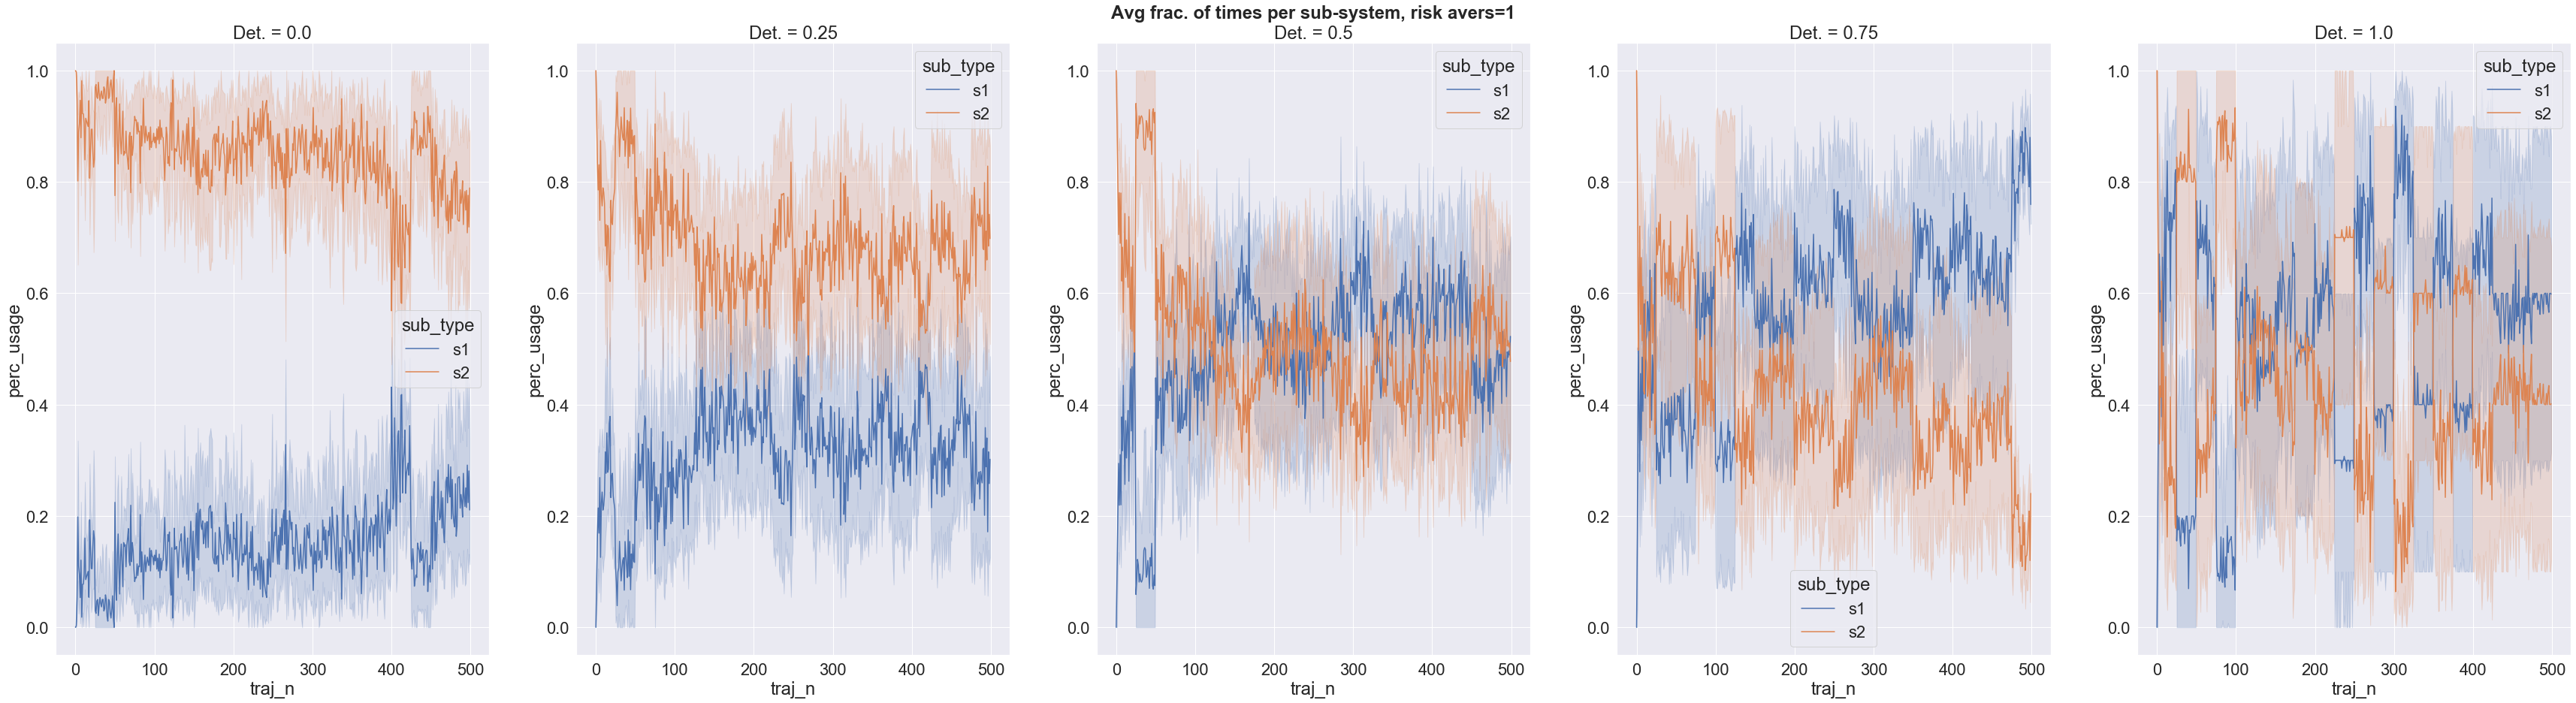

In [15]:
x='traj_n'
y='perc_usage'
#y='avg_reward'
#y='avg_time'
filename = y+'_risk'
title="Avg frac. of times per sub-system, risk avers="

plot_subtype(x,y,df,"sub_type",title,filename, list_threshold3=list_threshold3)

In [ ]:
mca_agents[4].__dict__.keys()

In [ ]:
x='traj_n'
y='avg_reward'
#y='avg_time'
filename = y+'_risk_'
title="Avg reward per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True)


In [ ]:
x='traj_n'
y='avg_time'
filename = y+'_time'
title="Avg time per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True, max_label=40)

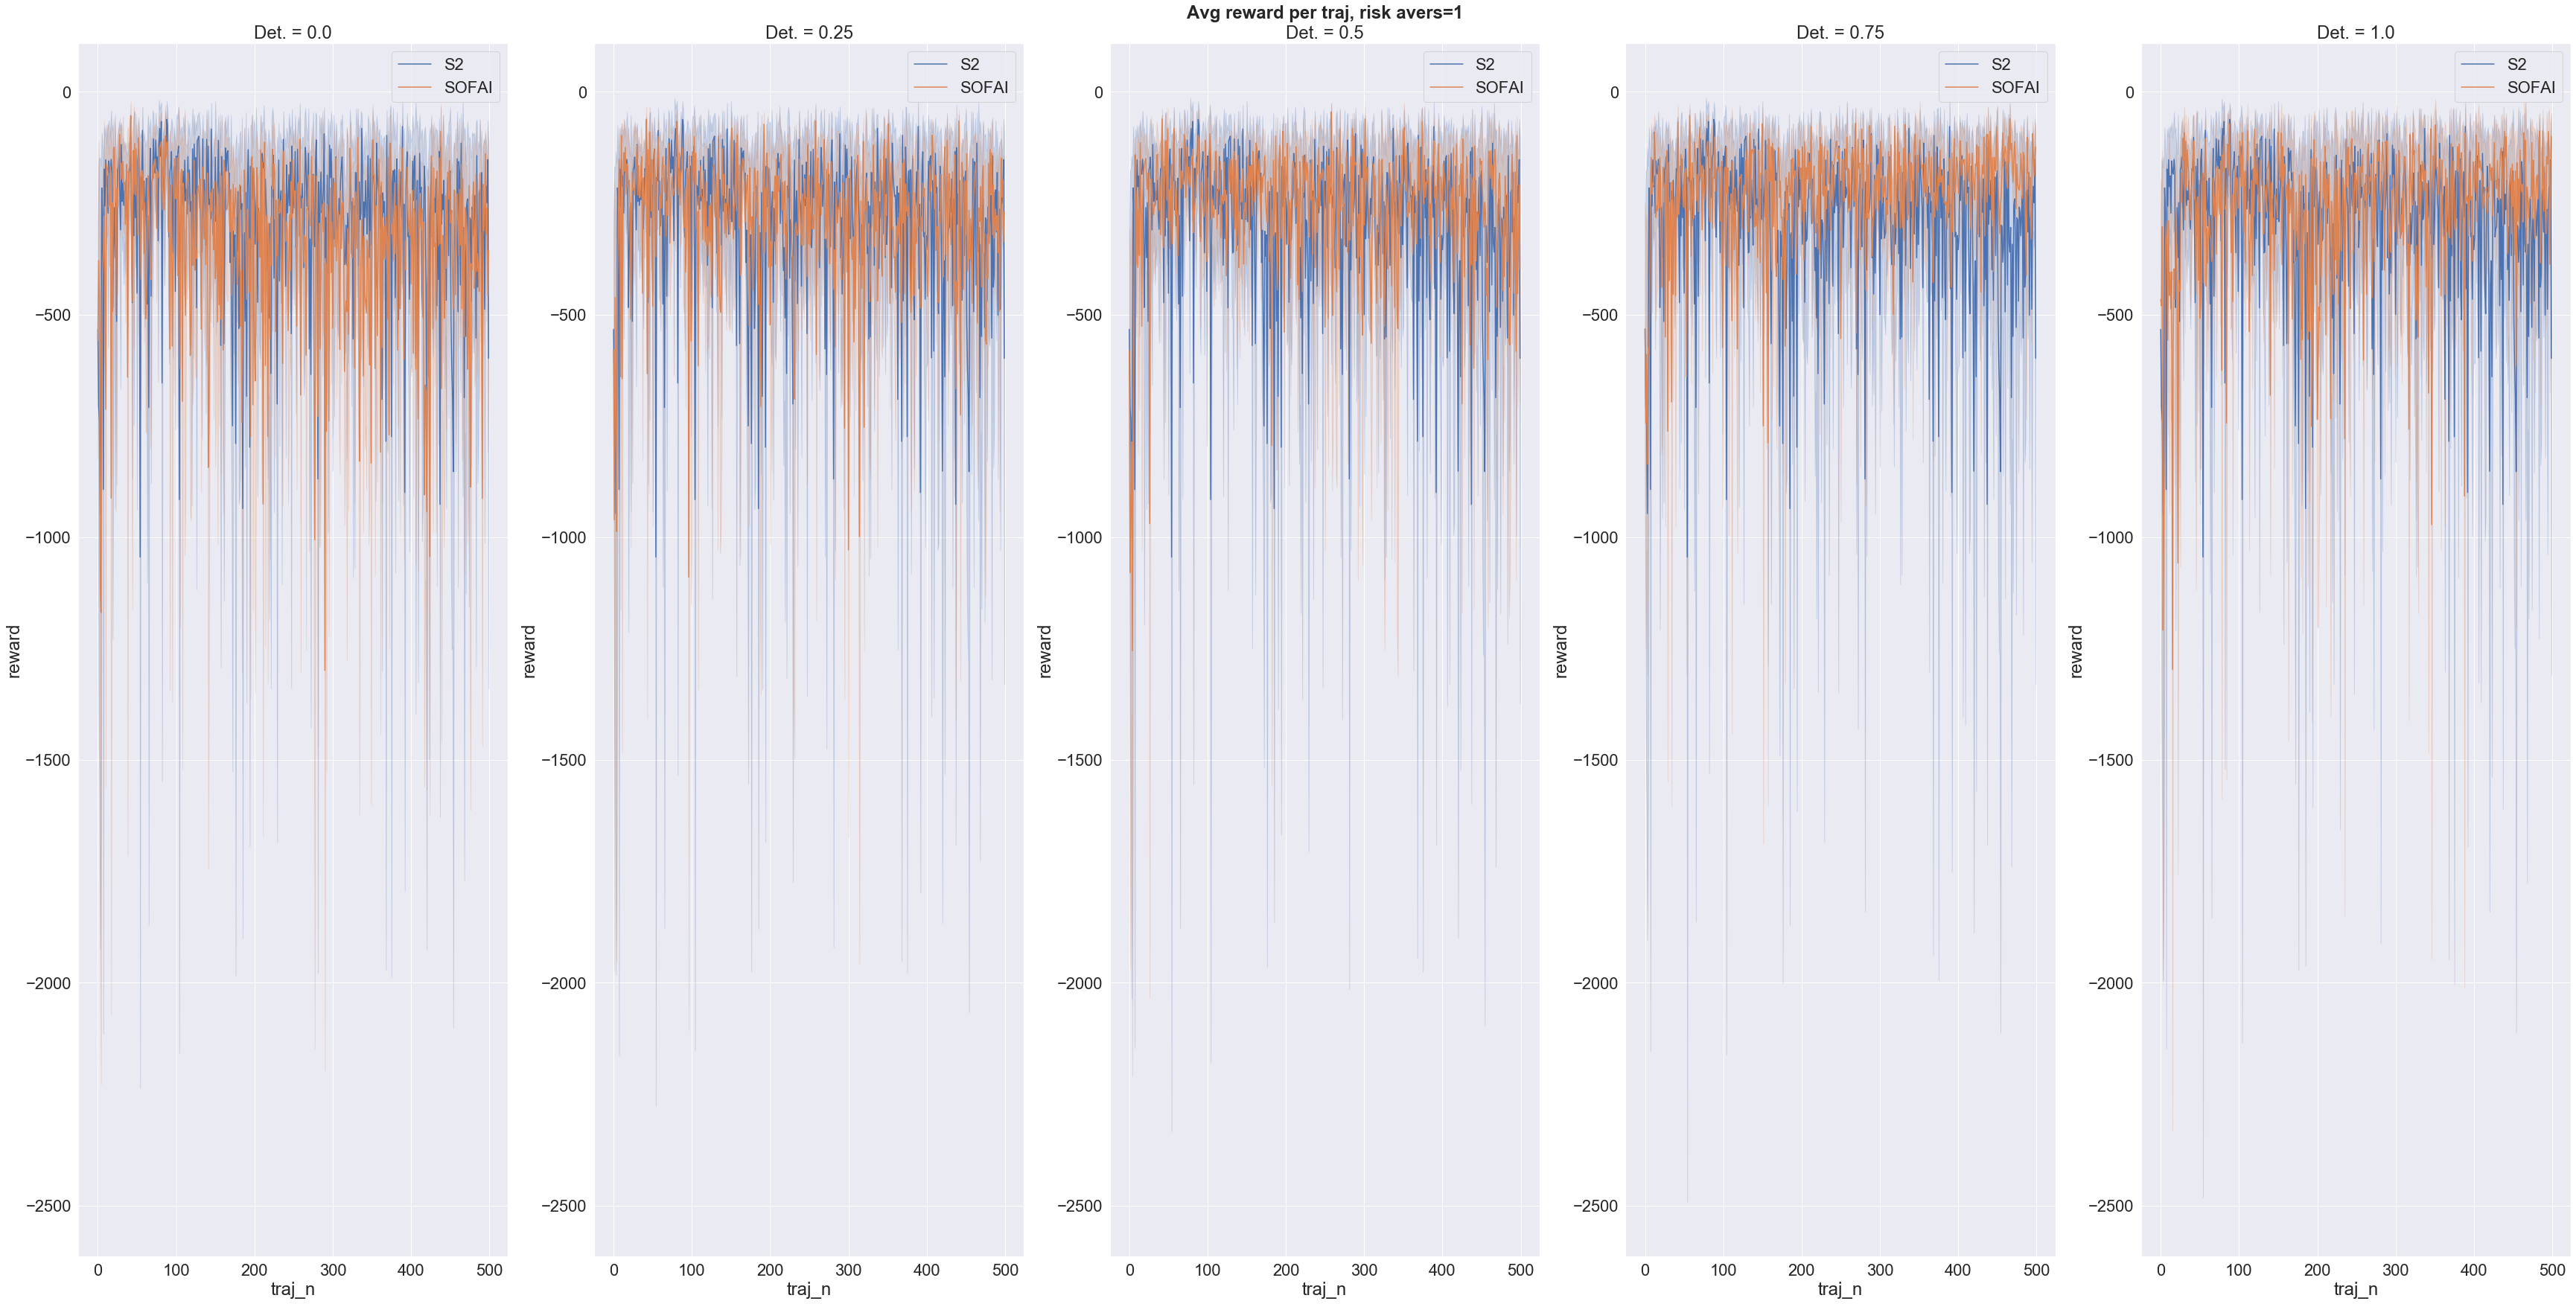

In [11]:
x='traj_n'
#y='perc_usage'
y='reward'
#y='time'


filename = 'avg_reward_per_traj'
title="Avg reward per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

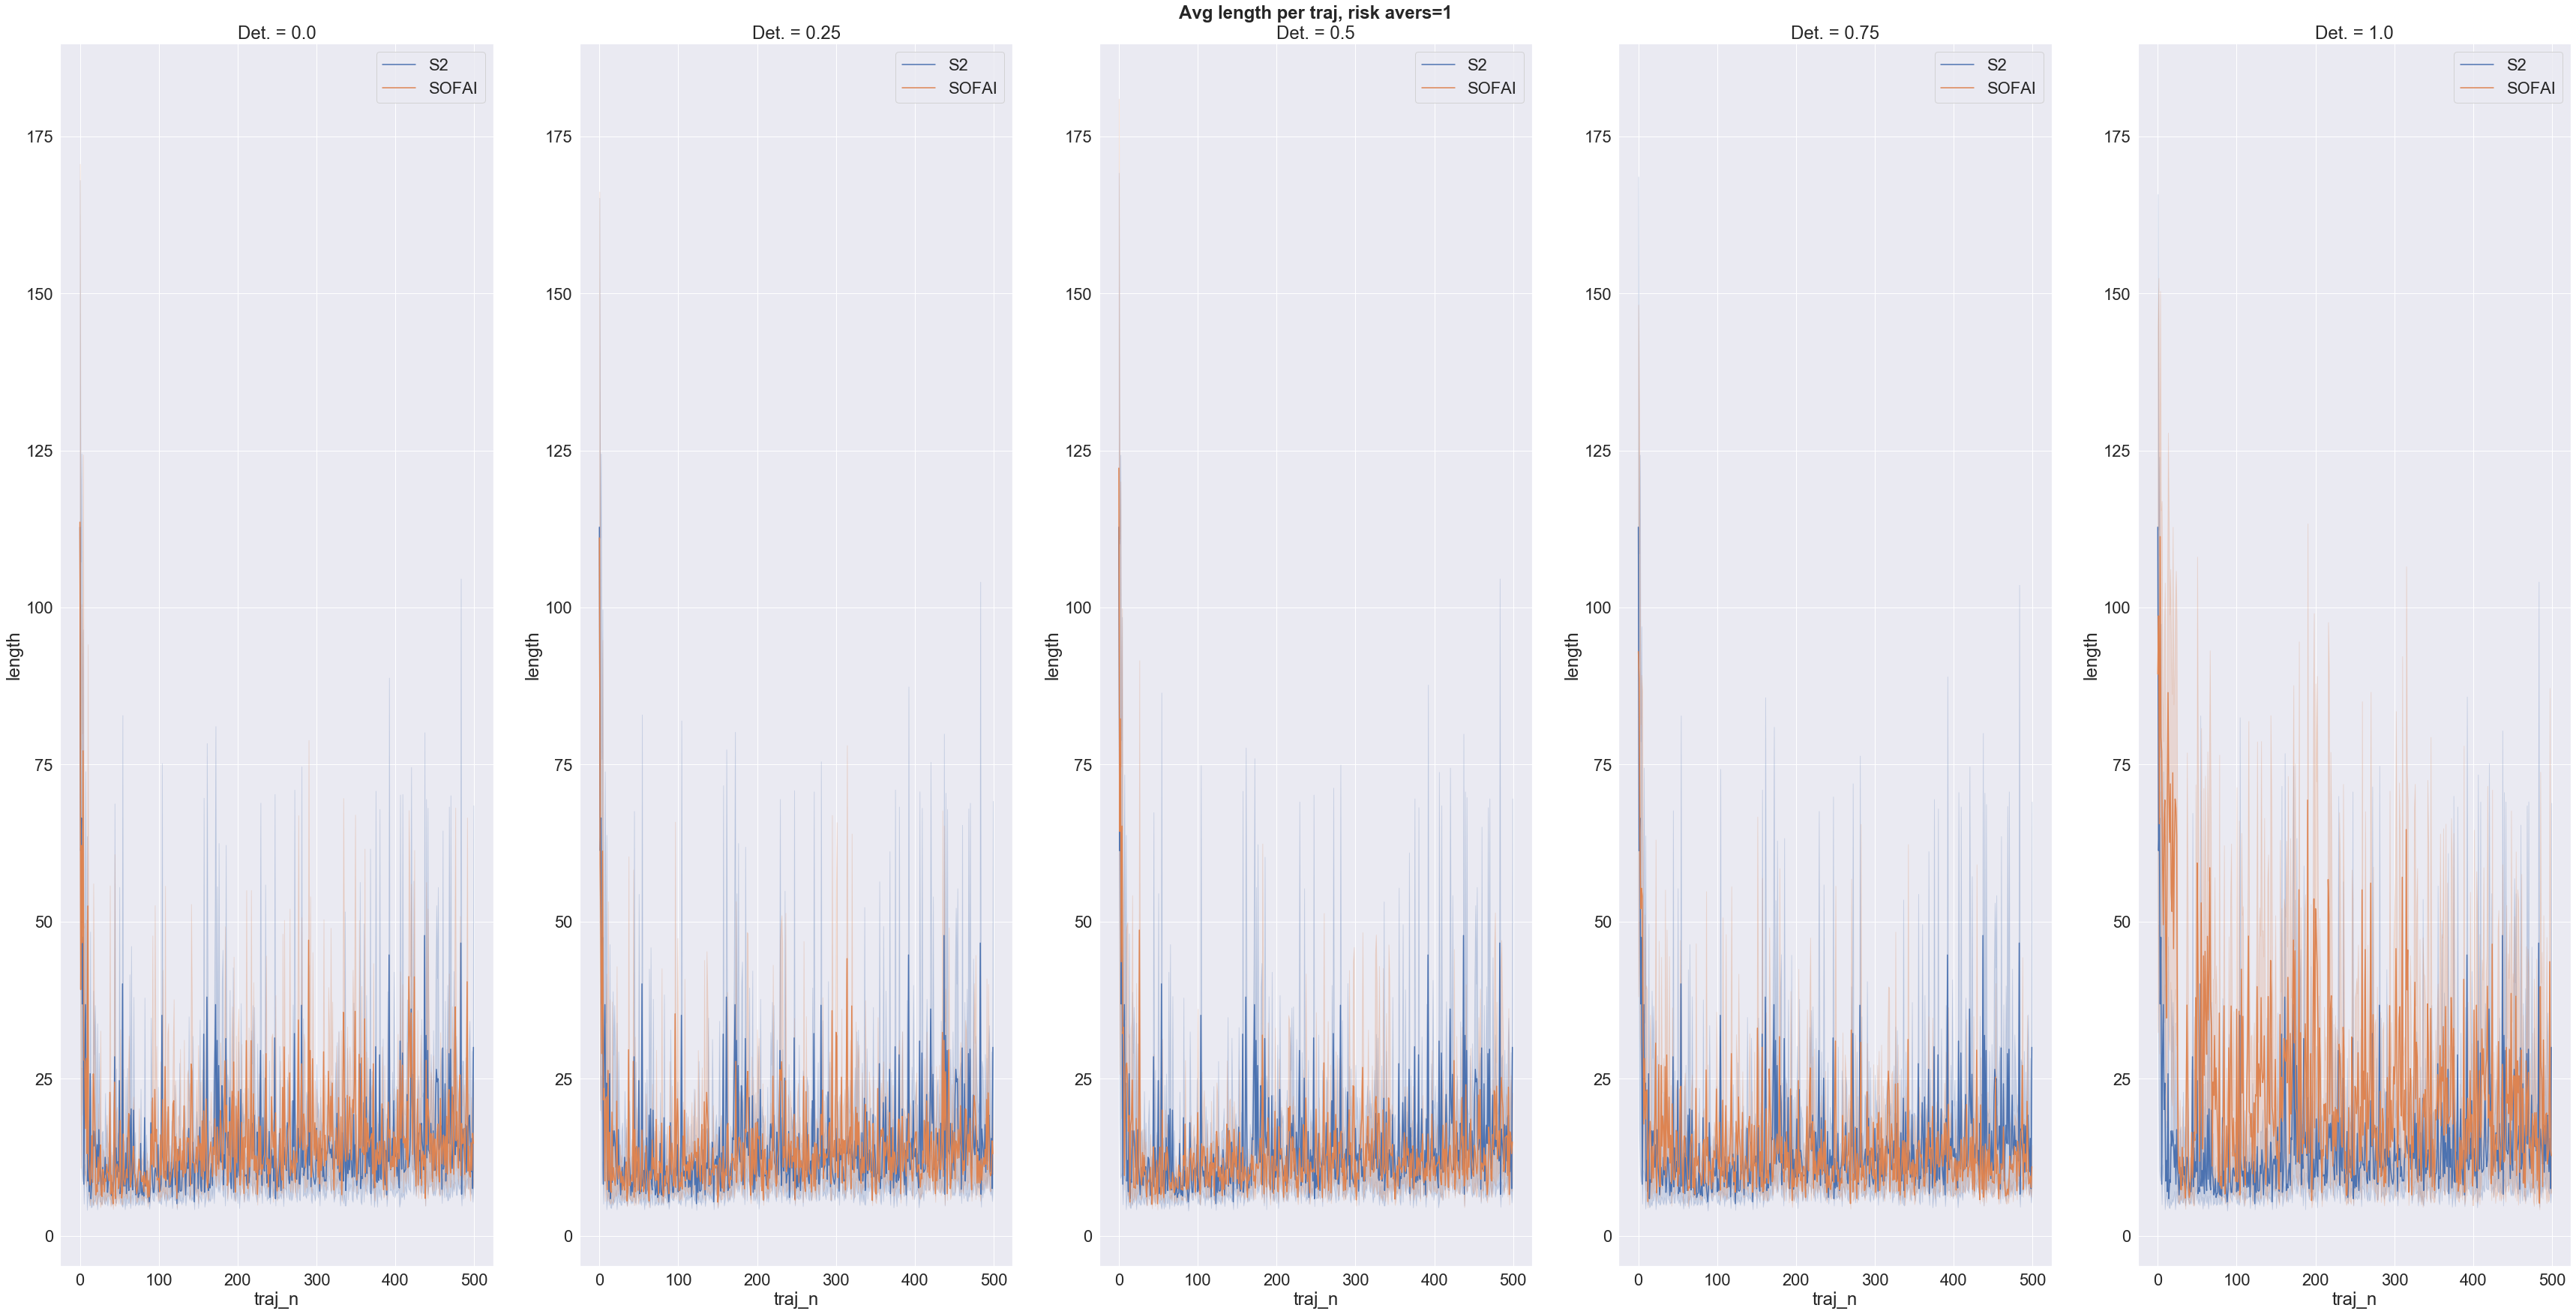

In [12]:
x='traj_n'
y='length'

filename = 'avg_length_per_traj'
title="Avg length per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

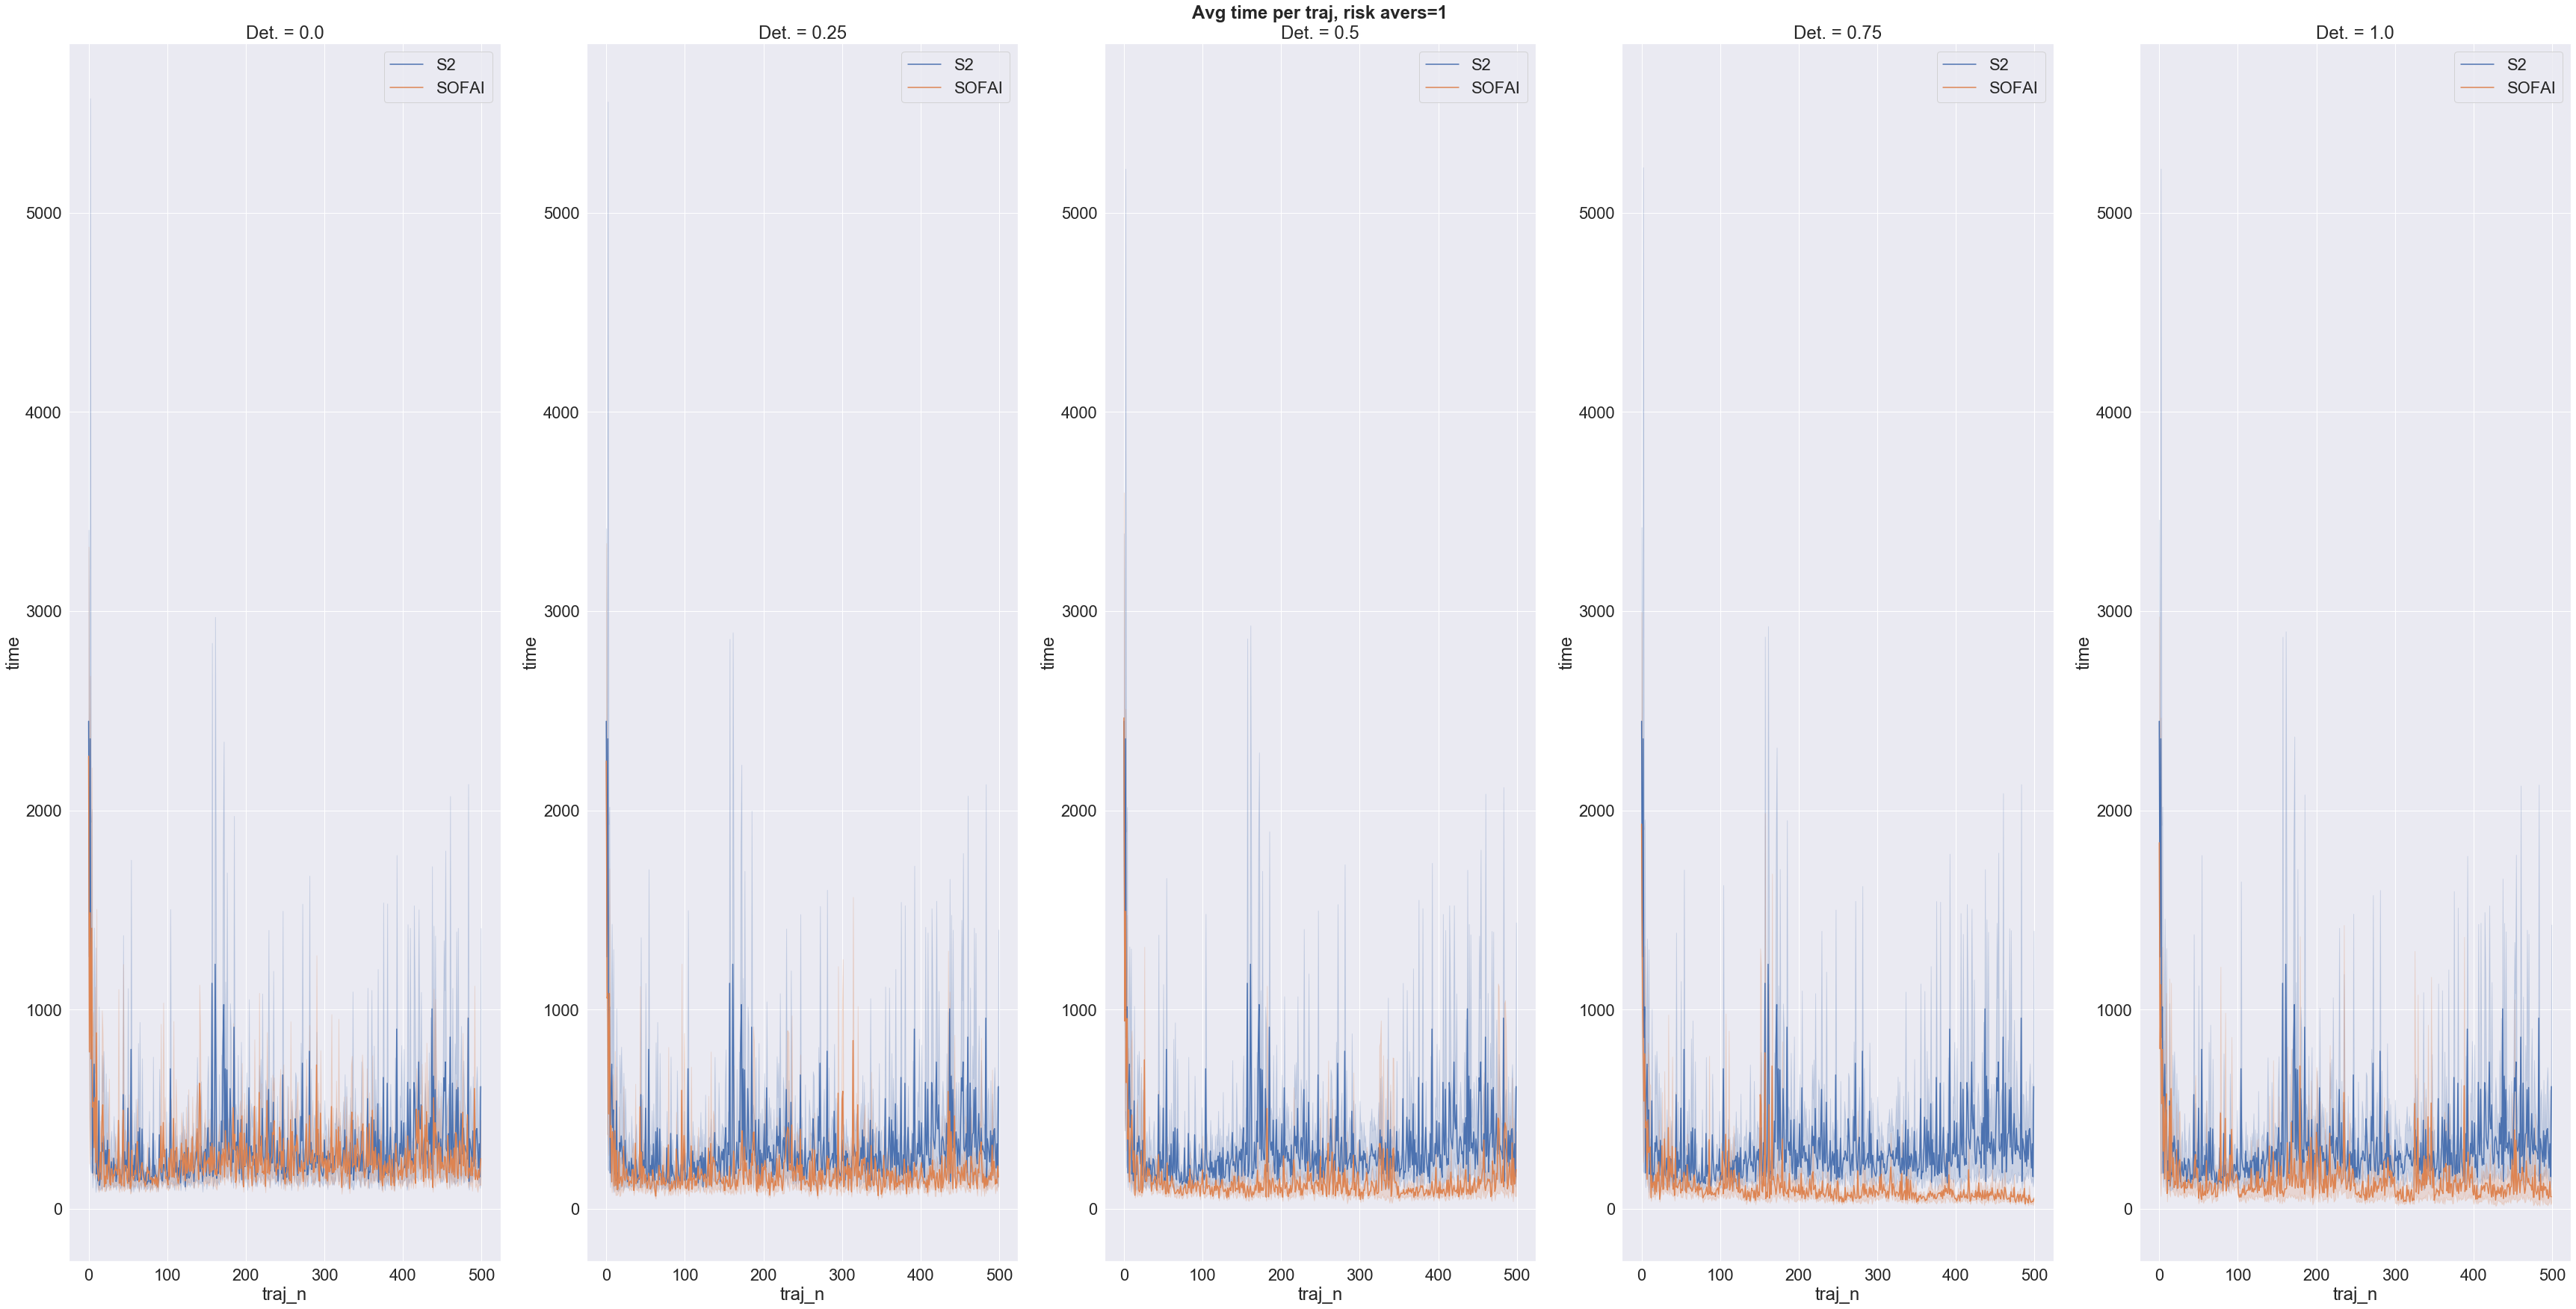

In [13]:
x='traj_n'
y='time'
filename = 'avg_time_withS1_per_traj'
title="Avg time per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

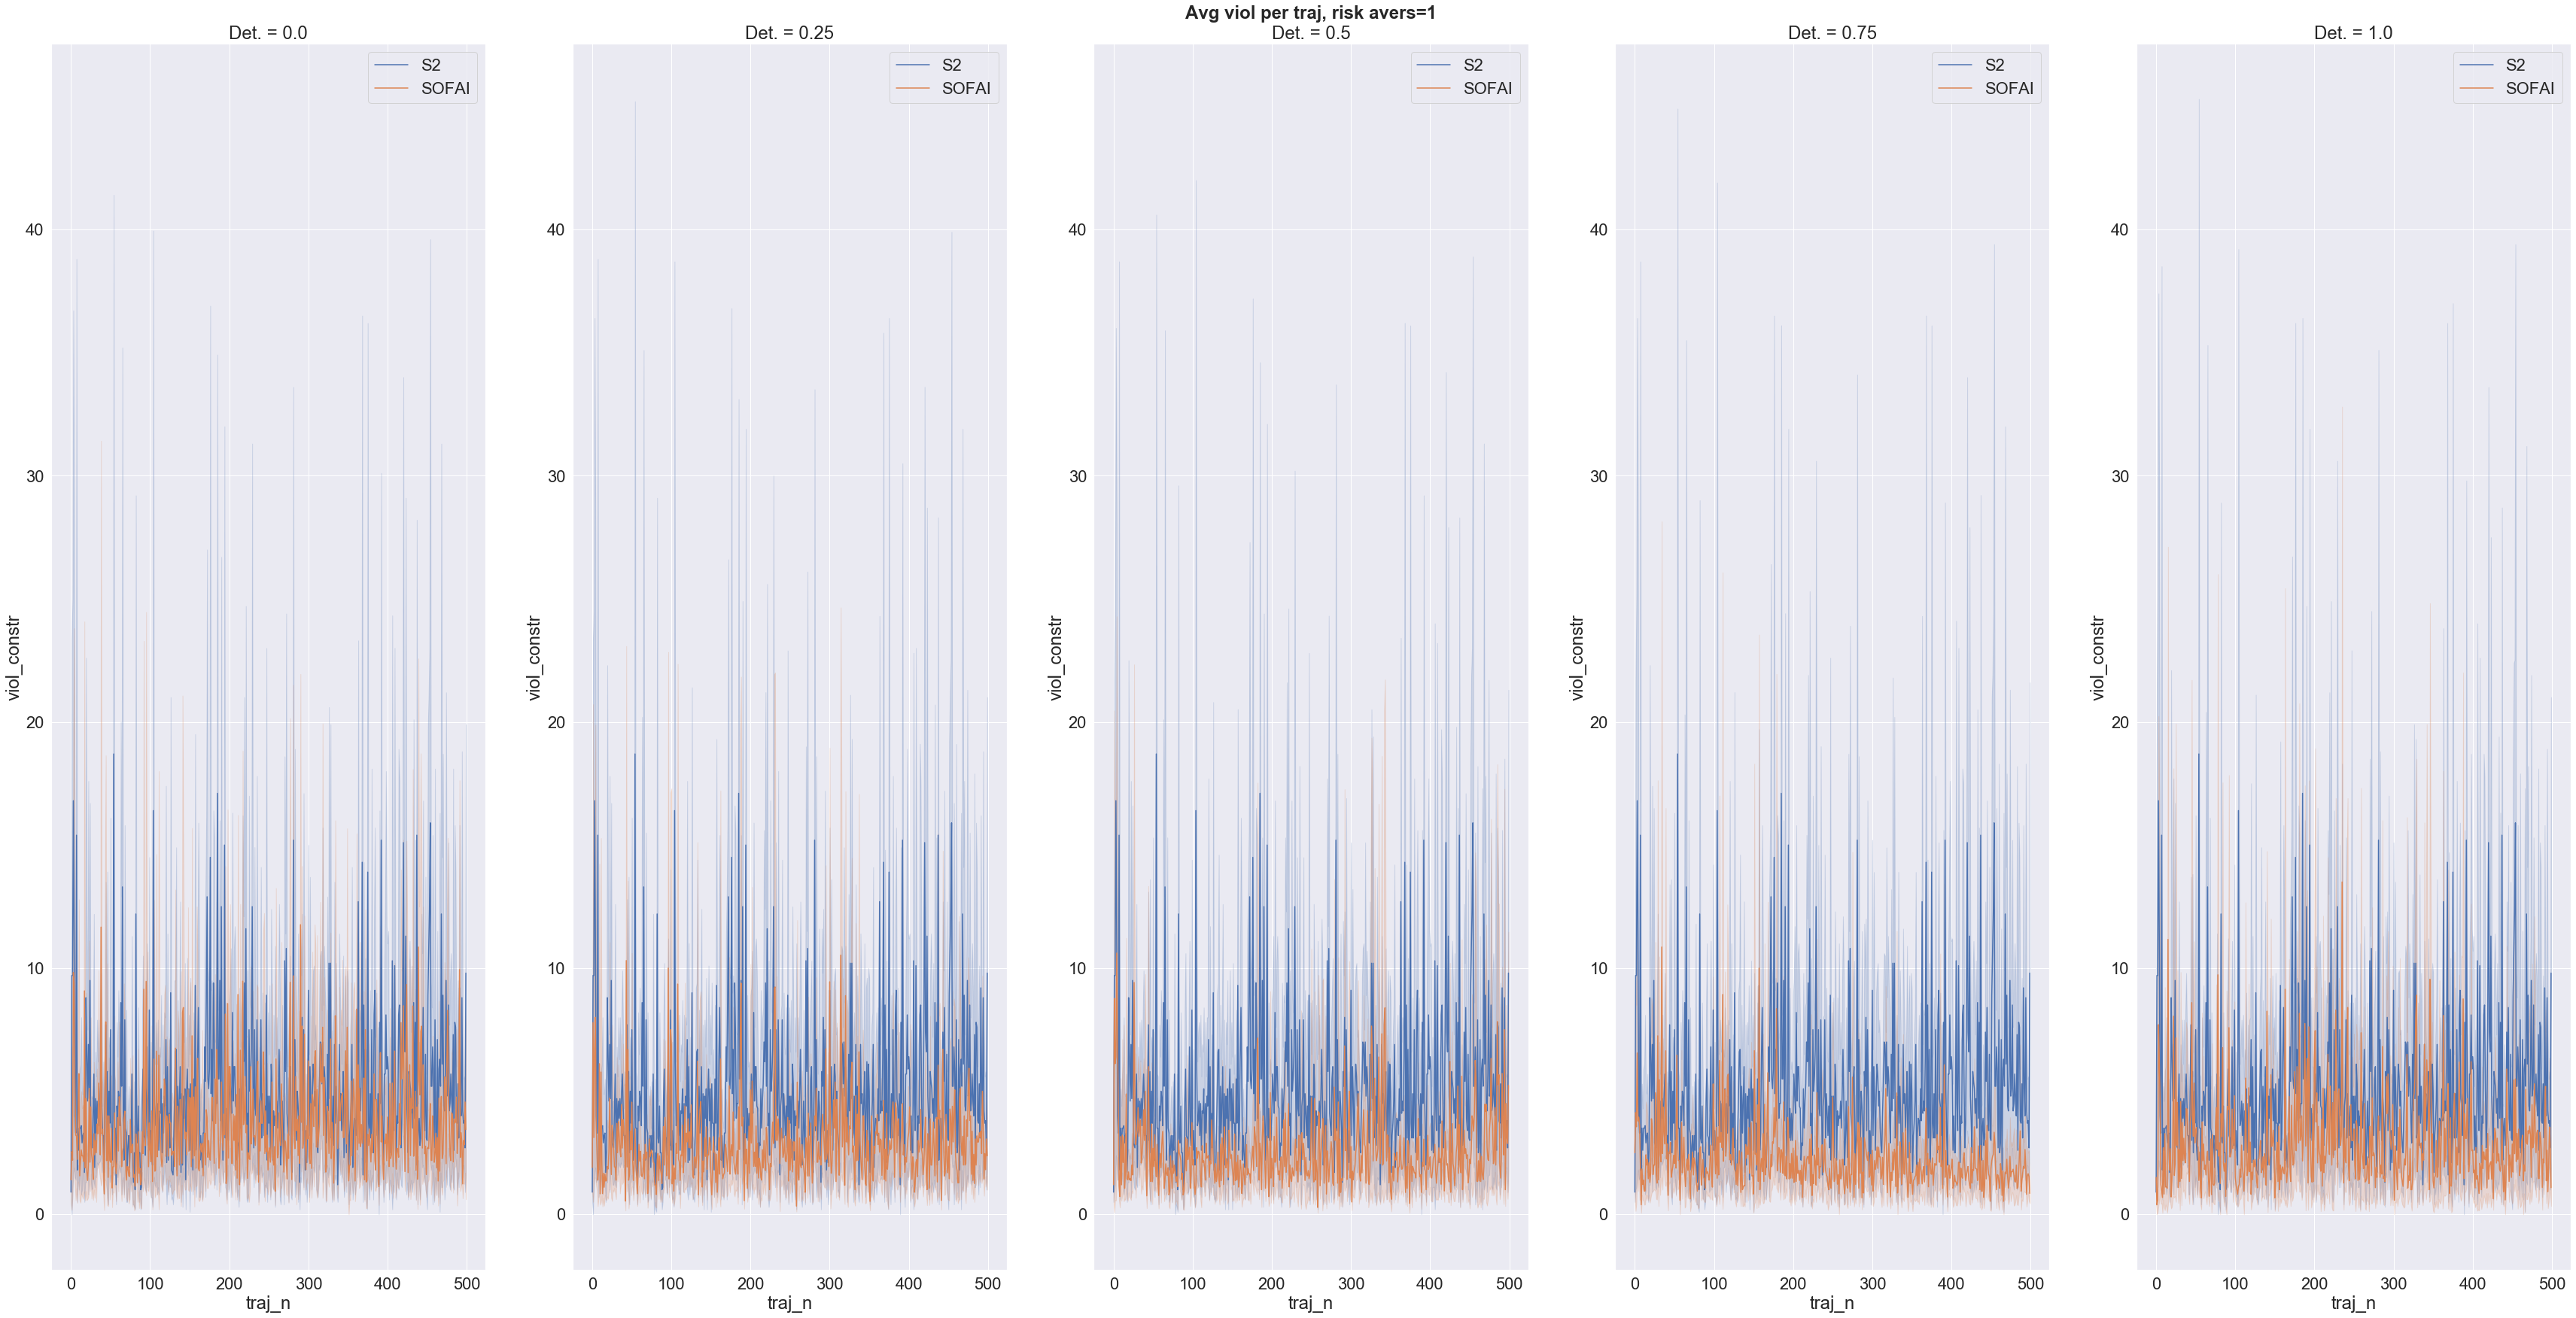

In [14]:
x='traj_n'
y='viol_constr'
filename = 'avg_viol_aggregated_per_traj'
title="Avg viol per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3, dropna=True)

In [ ]:
len(demo_list)

In [ ]:
mca_agents[4].modelSelf.grid.world.state_index_to_point(26)

In [ ]:
temp_dictionary = demo_list[-3].__dict__

In [ ]:
mca_agents[4].trajectory_stat[2]

In [ ]:
mca_agents[4].modelSelf.trajectories[:]

In [ ]:
r[4]

In [ ]:
blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)


In [ ]:
n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=True)

In [ ]:
print(mca_agents[4].modelSelf.getReward(26,1))
print(mca_agents[4].modelSelf.getRewardS2(26, maxLike=False, verbose=True))

In [ ]:
mca_agents[4].modelSelf.trajectories[0].transitions()[-1][2]

In [ ]:
mca_agents[4].modelSelf.ntra_per_transition[8,2,1]

In [ ]:
action = 1
print(sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print((list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys())))

for action in range(6):
    print(sum(np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys()))*np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))/sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print(mca_agents[4].modelSelf.ntra_per_stateAction_s2[(8, 2)])
print(mca_agents[4].modelSelf.ntra_per_stateAction[(8, 2)])

In [ ]:
#np.where(np.array(list(mca_agents[4].modelSelf.prob_s2[8,1,1,].values()))==11)
sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].keys()))/sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].values()))

In [ ]:
r = mca_agents[4].reflect(0.1)
print(sum(r[3]))
print(f"Temp: {mca_agents[4].temperature}")

In [ ]:
values_new = []
values = []
values_s2 = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    values_s2.append(-sum(mca_s2.action_reward[i])*sum(mca_s2.time_stat[i]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

In [ ]:
print(f"Temp: {mca_agents[4].temperature}")
threshold_delta = -0.0
compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)
#print(Trajectory(compare_traj[0]))

epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        #print(f"prima:{origTraj[transition]}")
        origTraj[transition] += 1
        #print(f"dopo:{origTraj[transition]}\n")
        
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))



distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
print(f"improvements {r[3]}")
values_new = []
values = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)


size = mca_agents[4].modelSelf.grid.world.size
epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        origTraj[transition] += 1	
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))

distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
#New is over old, i.e. it is worst, because of the higher time taken to compute the new trajectory
plt.figure(figsize=(20,10))
plt.plot(values_s2, label="S2")
plt.plot(values, label="Old")
plt.legend()

In [ ]:
for index, transition in enumerate(l.transitions()):
    print(index)

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
compare_traj

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[0:50])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]]

In [ ]:
i = 4
mca_agents[4].modelSelf.trajectories[i]

In [ ]:
mca_agents[3].modelSelf.trajectories[i]

In [ ]:
mca_agents[4].trajectory_stat[i]

In [ ]:
mca_agents[3].trajectory_stat[i]

In [ ]:
sum(map(sum,mca_agents[3].action_reward))

In [ ]:
sum(map(sum,mca_agents[4].action_reward))

In [ ]:
mca_agents[4].s1.count_random

In [ ]:
sum(np.reshape(newtraj, (-1,)))

In [ ]:
r[3]

In [ ]:
mca_s2.modelSelf.getM()

In [ ]:
mca_agents[4].modelSelf.getAvgPartialReward(63)

In [ ]:
for row in np.array(mca_agents[4].thresholds_stat):
    for action in row:
        print(action[1])

In [ ]:
df